# Fig. 4 Stroboscopic dynamics in a long chain, particle starting on a C site

Computed with the exact Floquet operator of the square wave (`stroboscopic_populations_exact`).


> Labelling: cells are counted from 1 in all figures. With sites $C_1, \dots, C_{101}$ the central site is $C_{51}$
> (0-based site index 150).

Output: `Data/Fig04_dynamics_C_site.npz`

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1]                 # .../paper_reproduction
DATA = ROOT / 'Data'

from diamond_chain import site_index, stroboscopic_populations_exact
from data_io import save_data

In [2]:
J = 1.0
phi = np.pi
Ncells = 100
w = 8
A = 1.2 * w
zeta = -1
ncycles = 400

initial_site = site_index('C', 51)
print('initial site index:', initial_site)

initial site index: 150


In [3]:
# Exact Floquet operator of the square wave (two matrix exponentials per period)
tvals, populations = stroboscopic_populations_exact(Ncells, phi, A, w, initial_site, ncycles, zeta=zeta, J=J)

np.float64(-0.6103793905643579)

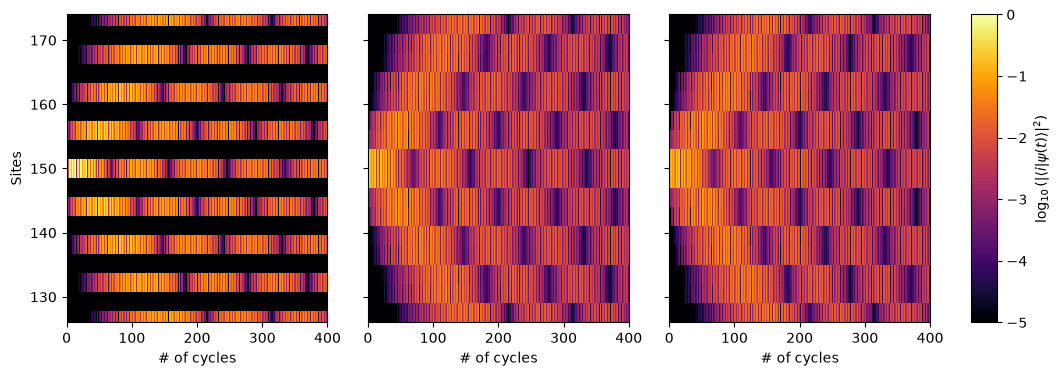

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(12, 4), width_ratios=[1, 1, 1, 0.1])

sites = np.linspace(0, 3 * Ncells, 3 * Ncells + 1)
T = 2 * np.pi / w

for i, ax in enumerate(axs[:-1]):

    pcm = ax.imshow(np.log10(populations[:, i::3].T + 1e-10),
         extent=[tvals.min() / T, tvals.max() / T, sites.min(), sites.max()],
         aspect='auto', origin='lower', vmin=-5 , vmax=0, interpolation = 'none', 
                   cmap = 'inferno')
    ax.set_xlabel(r'# of cycles')

    if i != 0:
        ax.set_yticklabels([])
    ax.set_ylim(126, 174)

plt.colorbar(pcm, cax = axs[-1], label=r'$\log_{10}(|\langle i | \psi(t)\rangle|^2)$')
axs[0].set_ylabel('Sites');

np.max(np.log10(populations[:, 3 * Ncells // 2 - 2] + 1e-10))

In [5]:
save_data(DATA / 'Fig04_dynamics_C_site.npz',
          parameters={'J': J, 'phi': phi, 'Ncells': Ncells, 'w': w, 'A': A, 'zeta': zeta,
                      'ncycles': ncycles, 'initial_site': initial_site},
          tvals=tvals, populations=populations)

Saved Data/Fig04_dynamics_C_site.npz: tvals, populations
